# Appliances Energy Prediction — Exploratory Data Analysis

## 1. Introduction

The objective of this project is to investigate household appliance energy consumption using the Appliances Energy Prediction dataset.

The dataset contains measurements collected at 10-minute intervals over approximately 4.5 months. It includes appliance energy consumption, indoor temperature and humidity measurements, and outdoor weather conditions.

This project will approach the problem as a time-series forecasting task, investigating how historical consumption patterns and environmental conditions can be used to predict future appliance energy consumption.

The first stage focuses on understanding the dataset, examining its characteristics, and identifying temporal patterns that may influence the forecasting process.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/energydata_complete.csv")

df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


## 2. Initial Dataset Inspection

The first step is to examine the structure and characteristics of the dataset before proceeding with any preprocessing.

This includes checking the dimensions, data types, missing values, duplicate observations and descriptive statistics of the numerical variables.

These checks provide an initial understanding of the data and help identify any potential issues that might need to be addressed in later stages.

In [5]:
print("Dataset dimensions:", df.shape)

df.info()

display(df.describe())

print("Missing values: ", df.isnull().sum().sum())

print("Duplicate rows: ", df.duplicated().sum())

Dataset dimensions: (19735, 29)
<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-nu

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


Missing values:  0
Duplicate rows:  0


## 3. Temporal Structure of the Dataset

Since the dataset contains measurements collected over time, it is important to examine the temporal structure of the observations.

The timestamp column will be converted to a datetime format so that the observations can be properly ordered and temporal intervals can be investigated.

The sampling frequency, chronological order and overall observation period will also be examined to ensure that the dataset is suitable for time-series analysis.

In [6]:
# Converting the date column to datetime format
df['date'] = pd.to_datetime(df['date'])

# Sorting observations chronologically
df = df.sort_values(by='date').reset_index(drop=True)

# First and last timestamps inspection
print("First observation:", df['date'].min())
print("Last observation:", df['date'].max())

# Checking whether the timestamps are in chronological order
print("Chronologically ordered:", df['date'].is_monotonic_increasing)

# Inspecting the first few timestamps
display(df['date'].head())

First observation: 2016-01-11 17:00:00
Last observation: 2016-05-27 18:00:00
Chronologically ordered: True


0   2016-01-11 17:00:00
1   2016-01-11 17:10:00
2   2016-01-11 17:20:00
3   2016-01-11 17:30:00
4   2016-01-11 17:40:00
Name: date, dtype: datetime64[us]

In [7]:
# Calculate the time difference between consecutive observations
time_differences = df['date'].diff()

# Display the most frequent time intervals
display(time_differences.value_counts().head(10))

# Check the minimum and maximum time intervals
print("Minimum interval:", time_differences.min())
print("Maximum interval:", time_differences.max())

date
0 days 00:10:00    19734
Name: count, dtype: int64

Minimum interval: 0 days 00:10:00
Maximum interval: 0 days 00:10:00


## 4. Appliance Energy Consumption Over Time

An initial visualization of appliance energy consumption over the entire observation period can help identify general trends, fluctuations and potential recurring patterns.

This provides an overview of how consumption changes over time and serves as a starting point for investigating possible temporal dependencies.

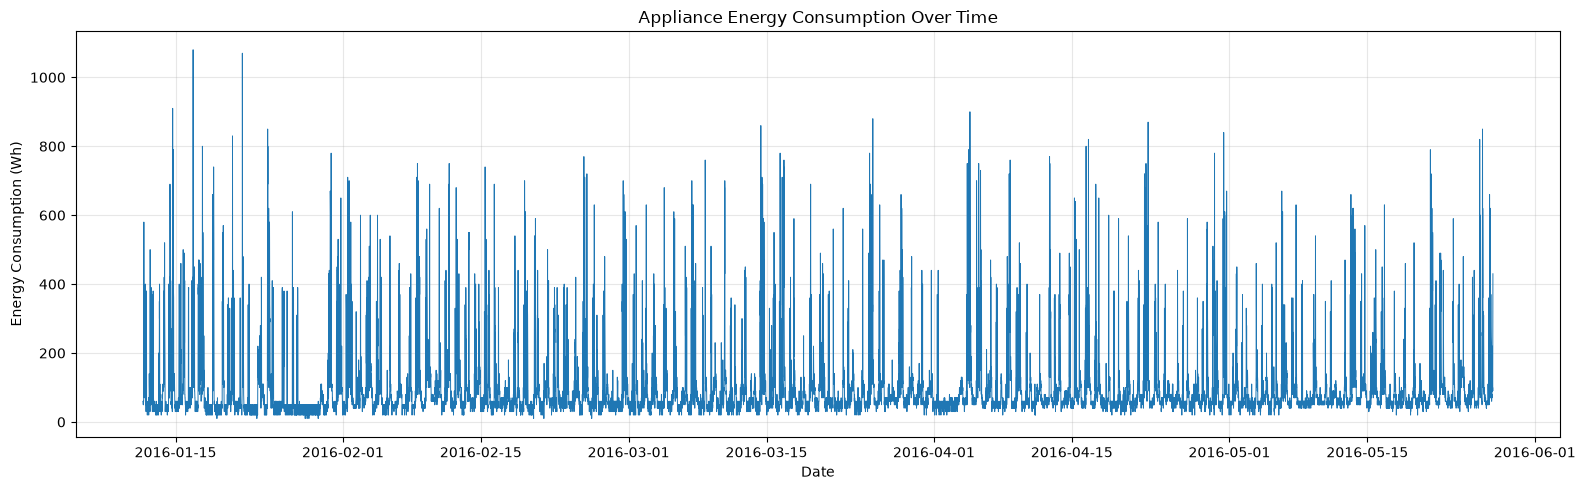

In [8]:
plt.figure(figsize=(16, 5))

plt.plot(df['date'], df['Appliances'], linewidth=0.7)

plt.title('Appliance Energy Consumption Over Time')
plt.xlabel('Date')
plt.ylabel('Energy Consumption (Wh)')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Initial Observations

The appliance energy consumption series exhibits considerable variability throughout the observation period. Most measurements appear concentrated at relatively low consumption levels, while frequent short-duration spikes reach several hundred Wh, occasionally exceeding 1,000 Wh.

No clear long-term increasing or decreasing trend can be identified from the initial visualization. However, the large fluctuations may obscure more gradual changes in average consumption.

Certain intervals, particularly toward the end of January, exhibit noticeably lower consumption levels. These periods may warrant further investigation.

Daily or weekly seasonal patterns are not immediately distinguishable at this scale. Further analysis using shorter observation windows and aggregated measurements is necessary to better understand the temporal behavior of the series.

### 4.1. Appliance Consumption Over a Shorter Period

Although the complete time series provides a useful overview of consumption variability, the large number of observations makes shorter-term patterns difficult to identify.

To examine these fluctuations more closely, a seven-day interval is selected and visualized separately. This allows changes within individual days to be observed more clearly and may reveal recurring consumption patterns.

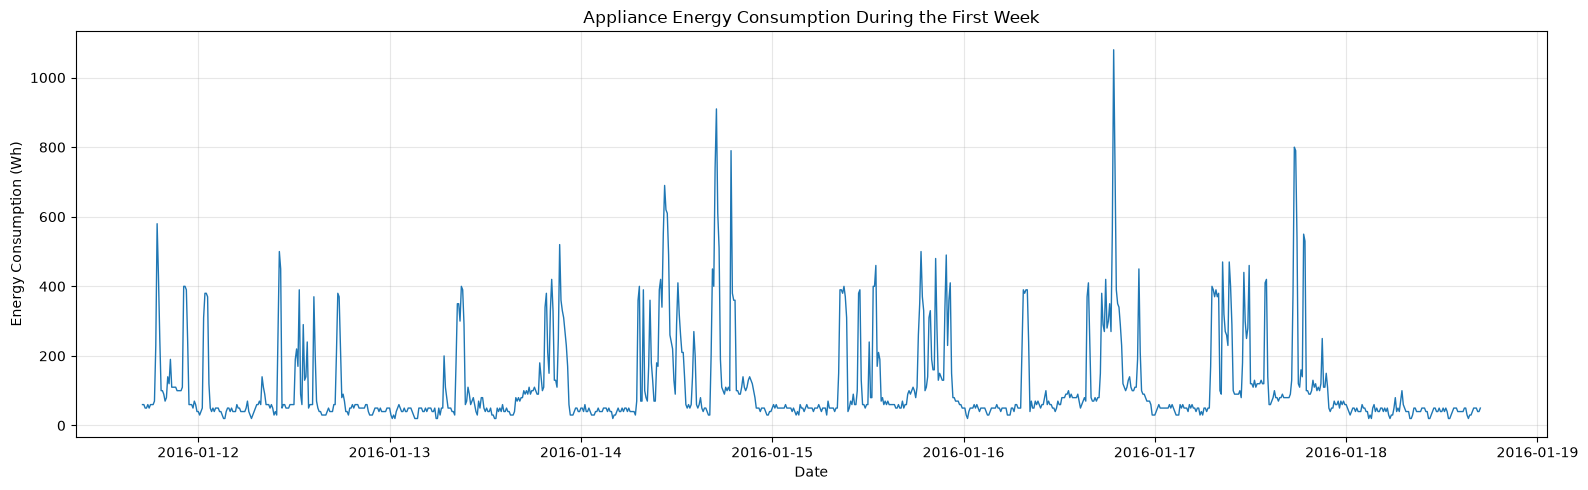

In [9]:
start_date = df['date'].min()
end_date = start_date + pd.Timedelta(days=7)

week_data = df[
    (df['date'] >= start_date) &
    (df['date'] < end_date)
]

plt.figure(figsize=(16, 5))

plt.plot(
    week_data['date'],
    week_data['Appliances'],
    linewidth=1
)

plt.title('Appliance Energy Consumption During the First Week')
plt.xlabel('Date')
plt.ylabel('Energy Consumption (Wh)')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4.2. Daily Average Appliance Consumption

The individual measurements exhibit considerable short-term variability, making it difficult to identify broader changes in consumption.

To investigate these changes, the observations are grouped by calendar day and their average appliance energy consumption is calculated.

This aggregation reduces short-term fluctuations and provides a clearer overview of how average consumption varies throughout the observation period. It can also help identify potential daily or longer-term patterns.

In [10]:
# Calculate the average appliance consumption for each day
daily_consumption = df.set_index('date')['Appliances'].resample('D').mean()

display(daily_consumption.head())

date
2016-01-11    136.666667
2016-01-12     85.694444
2016-01-13     97.013889
2016-01-14    151.388889
2016-01-15    125.347222
Freq: D, Name: Appliances, dtype: float64

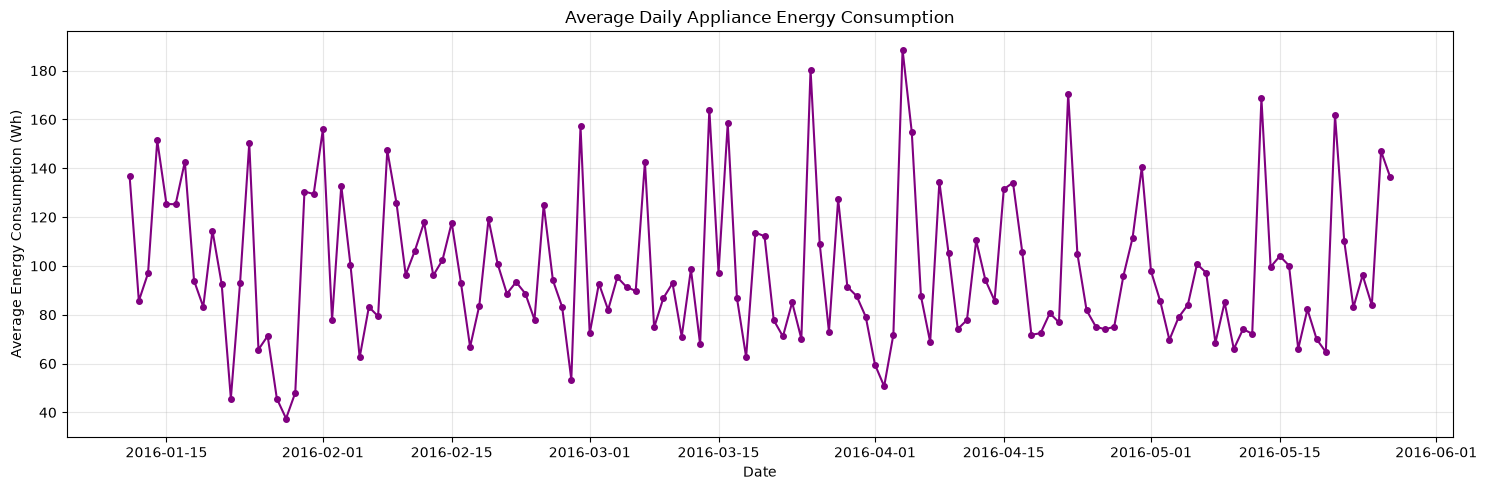

In [11]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_consumption.index,
    daily_consumption.values,
    marker='o',
    color='purple',
    markersize=4,
    linewidth=1.5
)

plt.title('Average Daily Appliance Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Average Energy Consumption (Wh)')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Observations

The daily average appliance consumption varies considerably throughout the observation period, with most days exhibiting average values between approximately 70 and 120 Wh. Several days show noticeably higher averages, while others have considerably lower consumption.

Despite these fluctuations, no consistent long-term increasing or decreasing trend is immediately apparent.

The daily averages provide a clearer overview of variations between days, but they do not preserve information about consumption patterns within individual days. Further analysis is therefore needed to investigate potential recurring intraday patterns.

### 4.3. Average Appliance Consumption by Hour of Day

To investigate potential daily seasonal patterns, appliance consumption is grouped according to the hour of the day.

The average consumption for each hour is calculated using observations from the entire dataset. This allows us to compare typical consumption levels at different times of the day and identify potential recurring intraday patterns.

In [12]:
# Calculate average appliance consumption for each hour of the day
hourly_consumption = df.groupby(
    df['date'].dt.hour
)['Appliances'].mean()

display(hourly_consumption)

date
0      52.785888
1      51.326034
2      49.075426
3      48.236010
4      49.355231
5      52.737226
6      57.712895
7      78.649635
8     106.143552
9     112.785888
10    125.377129
11    133.126521
12    123.637470
13    124.744526
14    108.284672
15    105.827251
16    119.902676
17    161.352657
18    190.364520
19    143.065693
20    126.982968
21     96.496350
22     69.148418
23     56.982968
Name: Appliances, dtype: float64

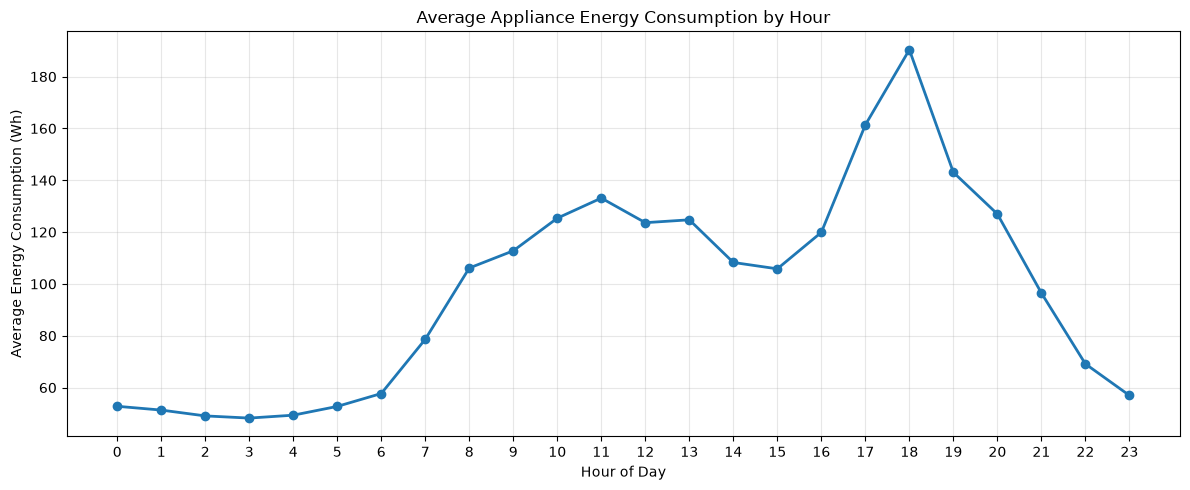

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker='o',
    linewidth=2
)

plt.title('Average Appliance Energy Consumption by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (Wh)')

plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Observations

The hourly average consumption reveals a noticeable daily pattern.

Consumption remains relatively low during nighttime, particularly between 00:00 and 06:00, with average values around 50–60 Wh. A considerable increase can be observed during the morning, reaching approximately 130 Wh by 11:00.

During the afternoon, consumption remains relatively stable before increasing again toward the evening. The highest average consumption occurs around 18:00, at approximately 190 Wh, followed by a gradual decrease throughout the remaining hours.

These observations suggest the presence of an intraday seasonal pattern, with appliance consumption varying according to the time of day. This makes temporal features such as the hour of day potentially useful for forecasting.

However, since the graph represents averages across the entire observation period, further analysis is needed to determine how consistent these patterns are across individual days.

### 4.4. Appliance Consumption by Day of Week and Hour

The previous analysis revealed noticeable variations in average consumption throughout the day. However, it did not distinguish between individual days of the week.

To investigate whether these patterns are consistent across the week, appliance consumption is grouped by both the day of the week and the hour of the day.

A heatmap is used to visualize the resulting averages, allowing potential differences between weekdays and weekends to be identified.

In [14]:
# Extract the day of the week and hour from each timestamp
df['day_of_week'] = df['date'].dt.day_of_week
df['hour'] = df['date'].dt.hour

# Calculate average consumption for each day and hour
weekly_hourly_consumption = df.pivot_table(
    values='Appliances',
    index='day_of_week',
    columns='hour',
    aggfunc='mean'
)

# Replace numerical day labels with their corresponding names
weekly_hourly_consumption.index = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

display(weekly_hourly_consumption)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Monday,53.684211,52.719298,50.964912,50.175439,50.438596,54.824561,56.228070,71.403509,94.035088,96.052632,...,151.228070,166.052632,144.736842,190.166667,189.083333,144.833333,148.916667,100.000000,76.166667,63.333333
Tuesday,66.083333,56.250000,49.083333,47.083333,48.833333,59.833333,53.000000,82.333333,87.416667,74.083333,...,73.583333,76.083333,82.416667,164.166667,192.583333,155.333333,143.500000,90.583333,61.916667,64.166667
Wednesday,52.083333,52.583333,49.500000,48.416667,52.000000,55.083333,73.666667,72.166667,112.000000,116.250000,...,105.666667,89.416667,109.750000,133.166667,199.500000,149.416667,140.166667,102.416667,68.750000,53.833333
Thursday,49.250000,49.416667,48.416667,46.750000,47.333333,53.083333,50.333333,78.750000,91.333333,98.666667,...,77.166667,71.000000,121.083333,179.666667,218.916667,140.416667,115.500000,90.916667,58.833333,52.083333
Friday,49.000000,48.916667,49.333333,48.166667,48.916667,49.333333,72.833333,104.250000,128.000000,150.750000,...,127.750000,124.333333,128.500000,149.583333,173.478261,127.543860,102.192982,84.824561,65.263158,49.824561
Saturday,49.122807,48.245614,47.543860,47.719298,47.982456,46.403509,48.771930,68.157895,99.122807,120.964912,...,138.070175,134.824561,154.561404,162.192982,185.000000,152.017544,106.315789,95.614035,80.175439,59.122807
Sunday,50.000000,51.052632,48.684211,49.473684,50.000000,50.263158,48.157895,72.280702,131.403509,133.333333,...,87.105263,82.368421,100.263158,150.000000,172.105263,130.964912,130.175439,111.228070,73.508772,56.228070


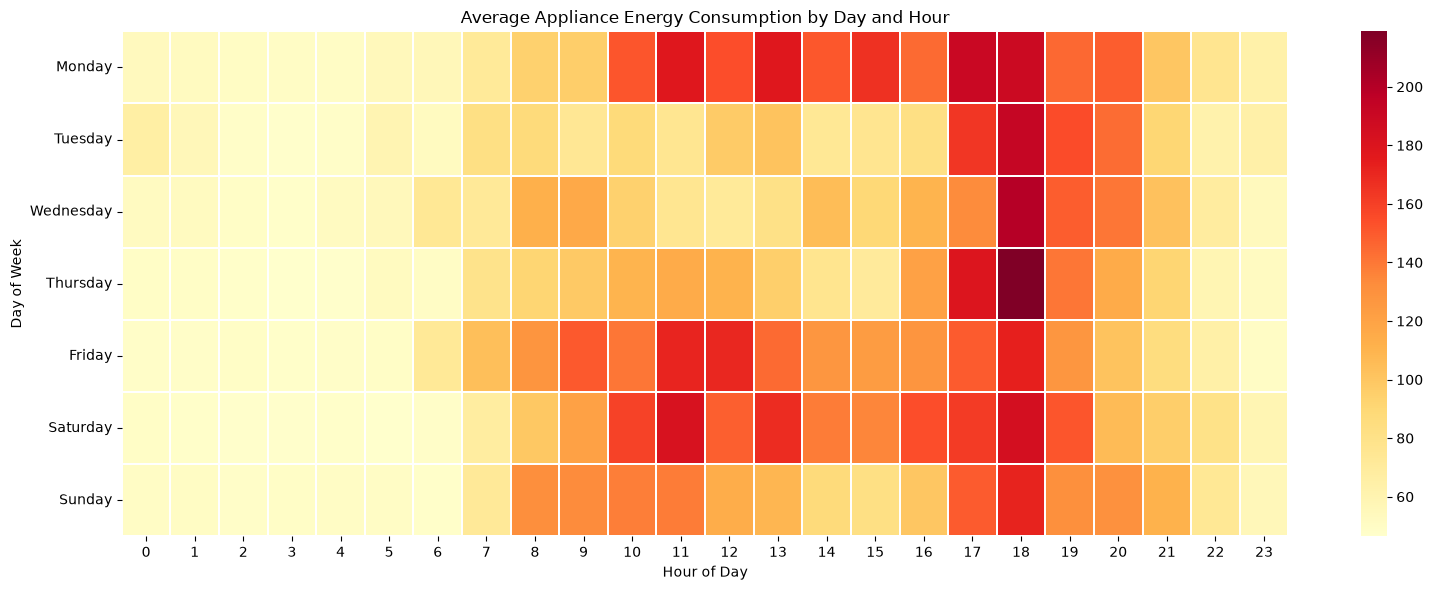

In [15]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    weekly_hourly_consumption,
    cmap='YlOrRd',
    annot=False,
    linewidths=0.3
)

plt.title('Average Appliance Energy Consumption by Day and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')

plt.tight_layout()
plt.show()

### Observations

The heatmap reveals noticeable differences in appliance consumption depending on both the hour of the day and the day of the week.

Consumption remains relatively low during nighttime across all seven days, particularly between 00:00 and 06:00. Higher consumption levels can generally be observed during the morning and evening hours, although their magnitude and distribution vary between weekdays.

A particularly noticeable increase occurs around 17:00–19:00, with Thursday exhibiting the highest average consumption around 18:00. Weekends also show distinct consumption profiles, suggesting that household activity may follow different patterns compared with weekdays.

These observations provide further evidence of recurring temporal patterns. Both the hour of the day and the day of the week may therefore be useful features for forecasting appliance energy consumption.

### 4.5. Autocorrelation Analysis

The previous visualizations revealed potential daily and weekly patterns in appliance energy consumption. To investigate the temporal dependencies between observations more directly, autocorrelation analysis is performed.

Autocorrelation measures the relationship between the values of a time series and its previous observations at different time lags. Unlike ordinary correlation, which examines the relationship between two potentially different variables, autocorrelation investigates the relationship between a variable and its own historical values.

The autocorrelation coefficient at lag $k$ is defined as:

$$\rho(k) = \text{Corr}(X_t, X_{t-k})$$

Where:
* $X_t$ represents the value of the time series at the current time $t$.
* $X_{t-k}$ represents the value of the same series $k$ observations earlier.
* $k$ represents the time lag, expressed as a number of observations.
* $\text{Corr}$ calculates the Pearson correlation coefficient between the two sets of values.

This analysis can help identify how strongly consumption depends on recent measurements and whether recurring patterns are present at specific intervals, such as one day or one week.


In [16]:
from statsmodels.tsa.stattools import acf

# Autocorrelation coefficients for the first 7 days
autocorrelation_values = acf(
    df['Appliances'],
    nlags=144 * 7,
    fft=True
)

# Display selected lag values
selected_lags = [1, 2, 6, 144, 1008]

for lag in selected_lags:
    print(
        f"Lag {lag}: "
        f"{autocorrelation_values[lag]:.4f}"
    )

Lag 1: 0.7530
Lag 2: 0.5340
Lag 6: 0.3235
Lag 144: 0.2147
Lag 1008: 0.2056


<Figure size 1500x500 with 0 Axes>

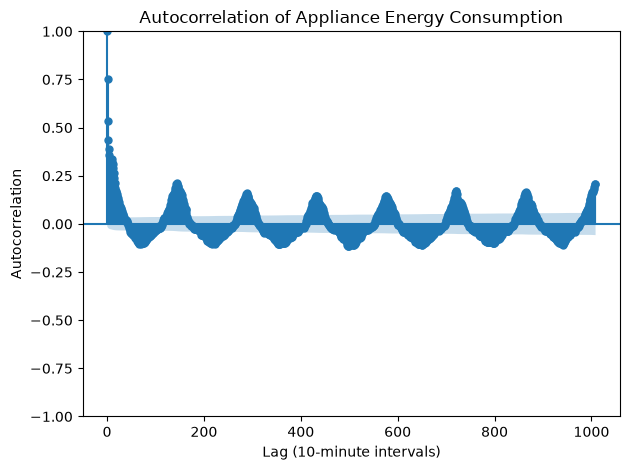

In [19]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(15, 5))

plot_acf(
    df['Appliances'],
    lags=144 * 7,
    alpha=0.05
)

plt.title('Autocorrelation of Appliance Energy Consumption')
plt.xlabel('Lag (10-minute intervals)')
plt.ylabel('Autocorrelation')

plt.tight_layout()
plt.show()

### 4.6. Partial Autocorrelation Analysis

While autocorrelation measures the overall relationship between observations separated by different time lags, partial autocorrelation investigates the relationship at a specific lag after accounting for the intermediate observations.

This distinction is useful because correlations at larger lags may partly result from their relationships with more recent observations.

PACF therefore provides additional insight into the temporal dependencies of the series and can help identify which historical observations have a stronger direct relationship with current consumption.

$$\phi_{kk} = \text{Corr}(X_t, X_{t-k} \mid X_{t-1}, X_{t-2}, \dots, X_{t-k+1})$$

In [21]:
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import pacf

partial_autocorrelation_values = pacf(
    df['Appliances'],
    nlags=40,
    method='ywm'
)

selected_lags = [1, 2, 3, 4, 5, 6, 12, 24]

for lag in selected_lags:
    print(
        f"Lag {lag}: "
        f"{partial_autocorrelation_values[lag]:.4f}"
    )

Lag 1: 0.7530
Lag 2: -0.0762
Lag 3: 0.1445
Lag 4: 0.0616
Lag 5: 0.0527
Lag 6: 0.0298
Lag 12: 0.0392
Lag 24: -0.0126


<Figure size 1500x500 with 0 Axes>

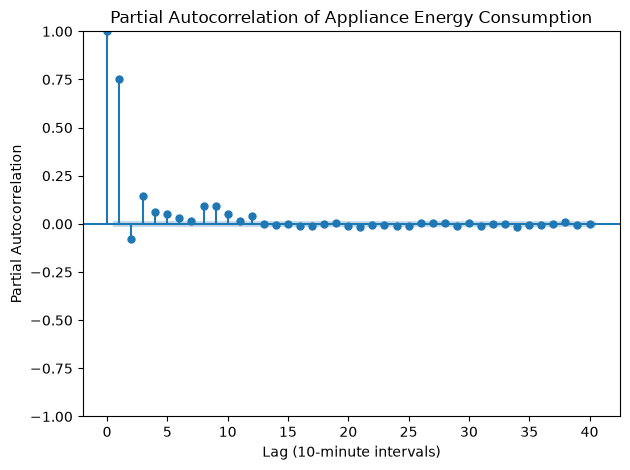

In [22]:
plt.figure(figsize=(15, 5))

plot_pacf(
    df['Appliances'],
    lags=40,
    alpha=0.05,
    method='ywm'
)

plt.title('Partial Autocorrelation of Appliance Energy Consumption')
plt.xlabel('Lag (10-minute intervals)')
plt.ylabel('Partial Autocorrelation')

plt.tight_layout()
plt.show()

### Observations

The partial autocorrelation analysis reveals a particularly strong relationship at lag 1, with a coefficient of approximately 0.753. This confirms that the immediately preceding consumption measurement contains substantial information about current consumption.

At lag 2, the partial autocorrelation decreases considerably to approximately -0.076, despite the corresponding ACF coefficient being approximately 0.534. This difference suggests that much of the correlation between observations separated by 20 minutes can be explained by their relationship with the intermediate observation.

A smaller positive partial autocorrelation can be observed at lag 3, with a coefficient of approximately 0.145. Most subsequent coefficients remain relatively close to zero.

Overall, the results suggest that recent consumption measurements, particularly the immediately preceding observation, have a strong relationship with current consumption. The PACF analysis also provides additional insight into which historical observations may contribute information beyond more recent measurements.

These findings will be considered when selecting historical lag features for the forecasting models. Their actual contribution will be evaluated experimentally during model development.

### 4.7. Summary of Temporal Analysis

The initial temporal analysis revealed several characteristics of appliance energy consumption.

The time-series visualization showed considerable variability throughout the observation period, with frequent short-duration increases in consumption. No clear long-term increasing or decreasing trend was immediately identifiable.

The hourly consumption profile revealed a noticeable daily pattern. Consumption generally remains lower during nighttime, increases throughout the morning and reaches its highest average levels during the evening, particularly around 18:00. The weekday and hourly heatmap also revealed differences in consumption patterns between individual days of the week.

Autocorrelation analysis indicated strong short-term temporal dependencies, with a coefficient of approximately 0.753 at lag 1. Recurring peaks at multiples of 144 observations also suggested a daily component in the series. Partial autocorrelation further showed that the strongest direct short-term relationship occurs at lag 1, while most subsequent coefficients are considerably smaller.

These observations suggest that historical appliance consumption, together with temporal information such as the hour and day of the week, may provide useful information for forecasting.

Further analysis of the numerical variables is necessary before finalizing the preprocessing and feature selection decisions.

## 5. Distribution and Correlation Analysis

In addition to examining the temporal characteristics of the dataset, it is important to investigate the distributions of the numerical variables and their relationships with appliance energy consumption.

This analysis can help identify skewed distributions, unusually high or low values, and potential relationships between the available features and the target variable.

### 5.1. Distribution of Appliance Energy Consumption

The distribution of the target variable is examined to understand how appliance energy consumption is spread across the observations.

A histogram is used to visualize the frequency of different consumption values, while a boxplot provides an additional overview of the distribution and its potential extreme values.

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

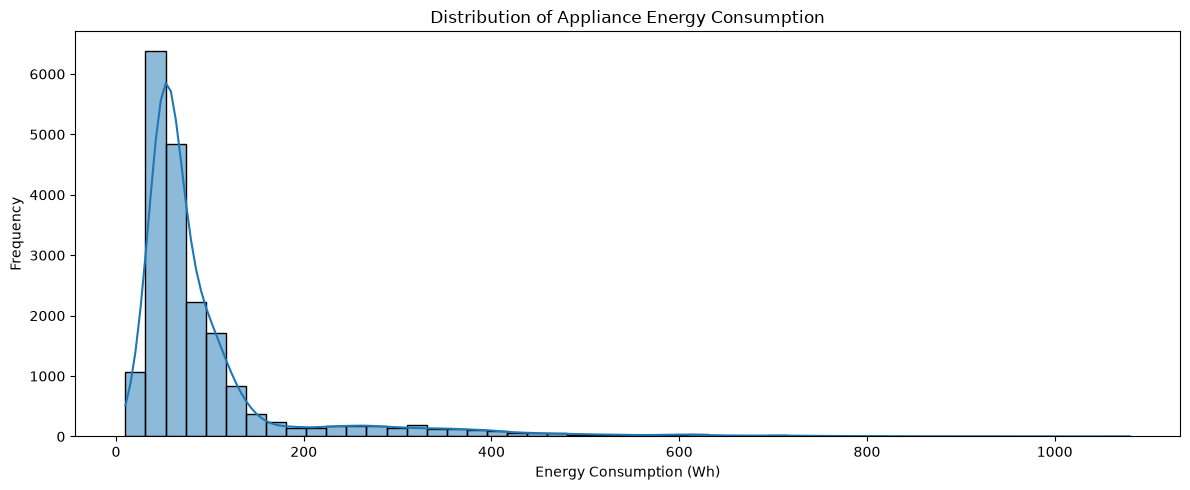

In [23]:
display(df['Appliances'].describe())

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x='Appliances',
    bins=50,
    kde=True
)

plt.title('Distribution of Appliance Energy Consumption')
plt.xlabel('Energy Consumption (Wh)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### Observations

The histogram reveals a strongly right-skewed distribution of appliance energy consumption. Most observations are concentrated at relatively low consumption values, particularly between approximately 20 and 150 Wh.

A considerably smaller number of observations exhibit much higher consumption levels, resulting in a long right tail that extends beyond 1,000 Wh.

The distribution is therefore not symmetrical, suggesting that unusually high consumption events occur relatively infrequently compared with normal consumption levels.

This characteristic is important for the subsequent modelling stage, as extreme values may influence evaluation metrics such as RMSE. A logarithmic transformation may also be worth investigating, although no transformation or removal of observations will be performed at this stage.

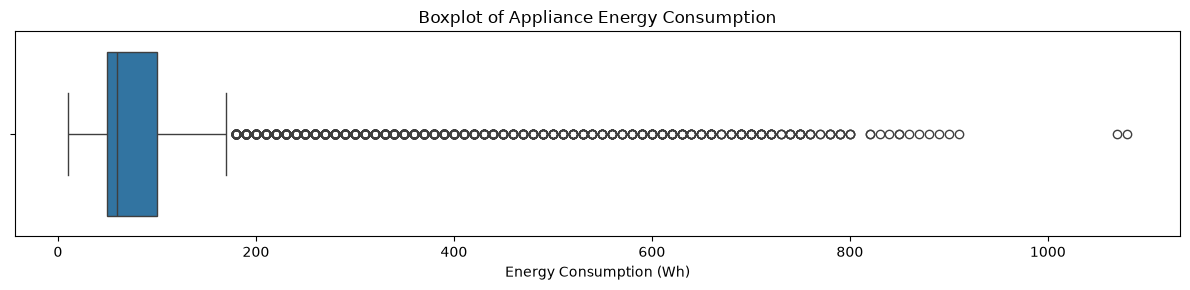

Q1: 50.0
Q3: 100.0
IQR: 50.0
Lower boundary: -25.0
Upper boundary: 175.0
Number of potential outliers: 2138
Percentage of potential outliers: 10.83 %


In [25]:
plt.figure(figsize=(12, 3))

sns.boxplot(x=df['Appliances'])

plt.title('Boxplot of Appliance Energy Consumption')
plt.xlabel('Energy Consumption (Wh)')

plt.tight_layout()
plt.show()

Q1 = df['Appliances'].quantile(0.25)
Q3 = df['Appliances'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Appliances'] < lower_bound) |
    (df['Appliances'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)
print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:", 
      round(len(outliers) / len(df) * 100, 2), "%")

### Observations

The boxplot reveals a relatively concentrated central distribution of appliance energy consumption, with a considerable number of observations extending beyond the upper whisker.

Using the conventional 1.5 × IQR rule, these observations are classified as potential outliers. Most of them occur on the higher end of the consumption range, with some values exceeding 1,000 Wh.

This reinforces the positive skewness observed in the histogram and indicates that unusually high consumption measurements are relatively common compared with the central distribution.

However, these observations cannot automatically be considered erroneous, as they may represent genuine periods of increased appliance usage. Their removal is therefore not justified based solely on the boxplot.

### 5.2. Distribution of Numerical Features

The distributions of the remaining numerical attributes are examined to understand their ranges, variability and general characteristics.

Histograms are used to identify potential skewness, unusual distributions and differences in the spread of the variables. This analysis also provides an opportunity to investigate attributes that may be redundant or have limited predictive relevance.

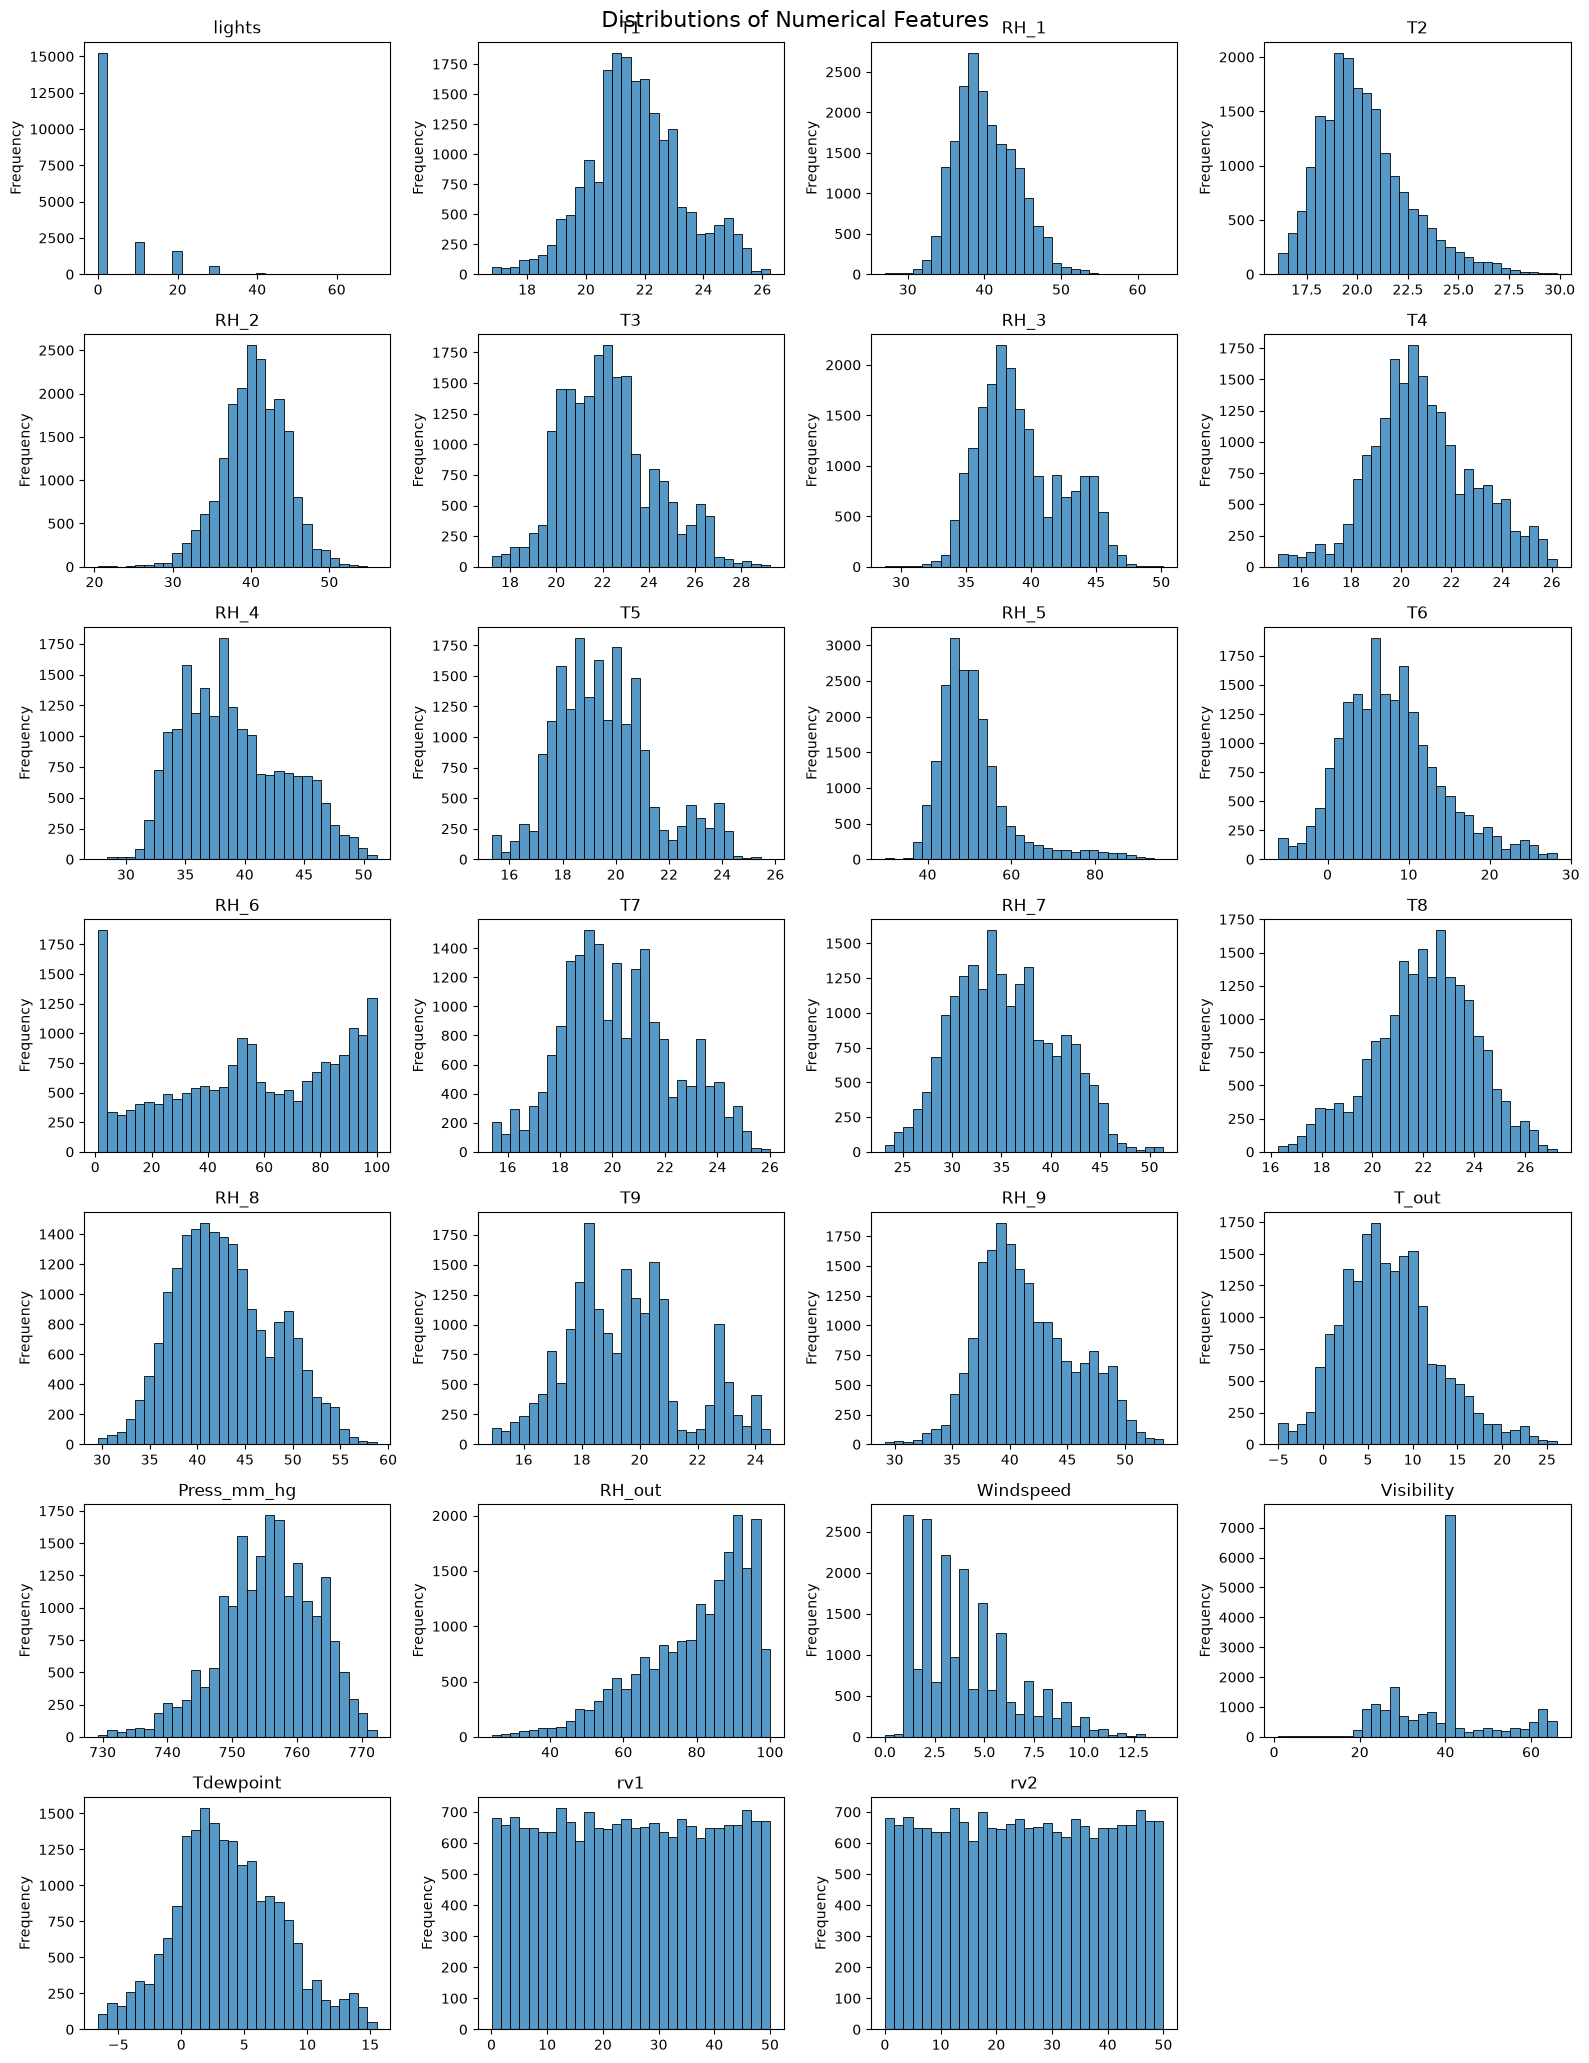

In [ ]:
numerical_features = df.select_dtypes(include='number').columns.drop(
    ['Appliances', 'day_of_week', 'hour'],
    errors='ignore'
)

n_cols = 4
n_rows = int(np.ceil(len(numerical_features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, n_rows * 3)
)

axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequency')

for i in range(len(numerical_features), len(axes)):
    fig.delaxes(axes[i])

plt.suptitle('Distributions of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

In [27]:
print("Are rv1 and rv2 identical?",
      df['rv1'].equals(df['rv2']))

print("Correlation between rv1 and rv2:",
      df['rv1'].corr(df['rv2']))

print("Unique values in rv1:", df['rv1'].nunique())
print("Unique values in rv2:", df['rv2'].nunique())

Are rv1 and rv2 identical? True
Correlation between rv1 and rv2: 1.0
Unique values in rv1: 19735
Unique values in rv2: 19735


### Observations

The numerical features exhibit different distributions and ranges depending on the type of measurement.

The indoor temperature variables are generally concentrated around similar temperature ranges, although some differences in their distributions can be observed. The humidity variables also exhibit varying distributions, with some showing noticeable skewness or concentrations around particular values.

Among the remaining environmental attributes, wind speed exhibits a positively skewed distribution, while atmospheric pressure is relatively concentrated within a narrow range. The visibility variable also shows a pronounced concentration around a particular value.

The `lights` attribute contains a large number of zero observations, which represent meaningful periods without lighting consumption rather than missing values.

Finally, `rv1` and `rv2` exhibit approximately uniform distributions, consistent with their documented purpose as artificial random variables. Their redundancy will be verified before deciding to exclude them from the predictive feature set.

### 5.3. Correlation Analysis

Correlation analysis is performed to investigate the linear relationships between the numerical attributes.

A correlation matrix is used to examine both the relationships between individual features and their association with appliance energy consumption.

This analysis can help identify potentially relevant predictors and highly correlated features that may contain overlapping information.

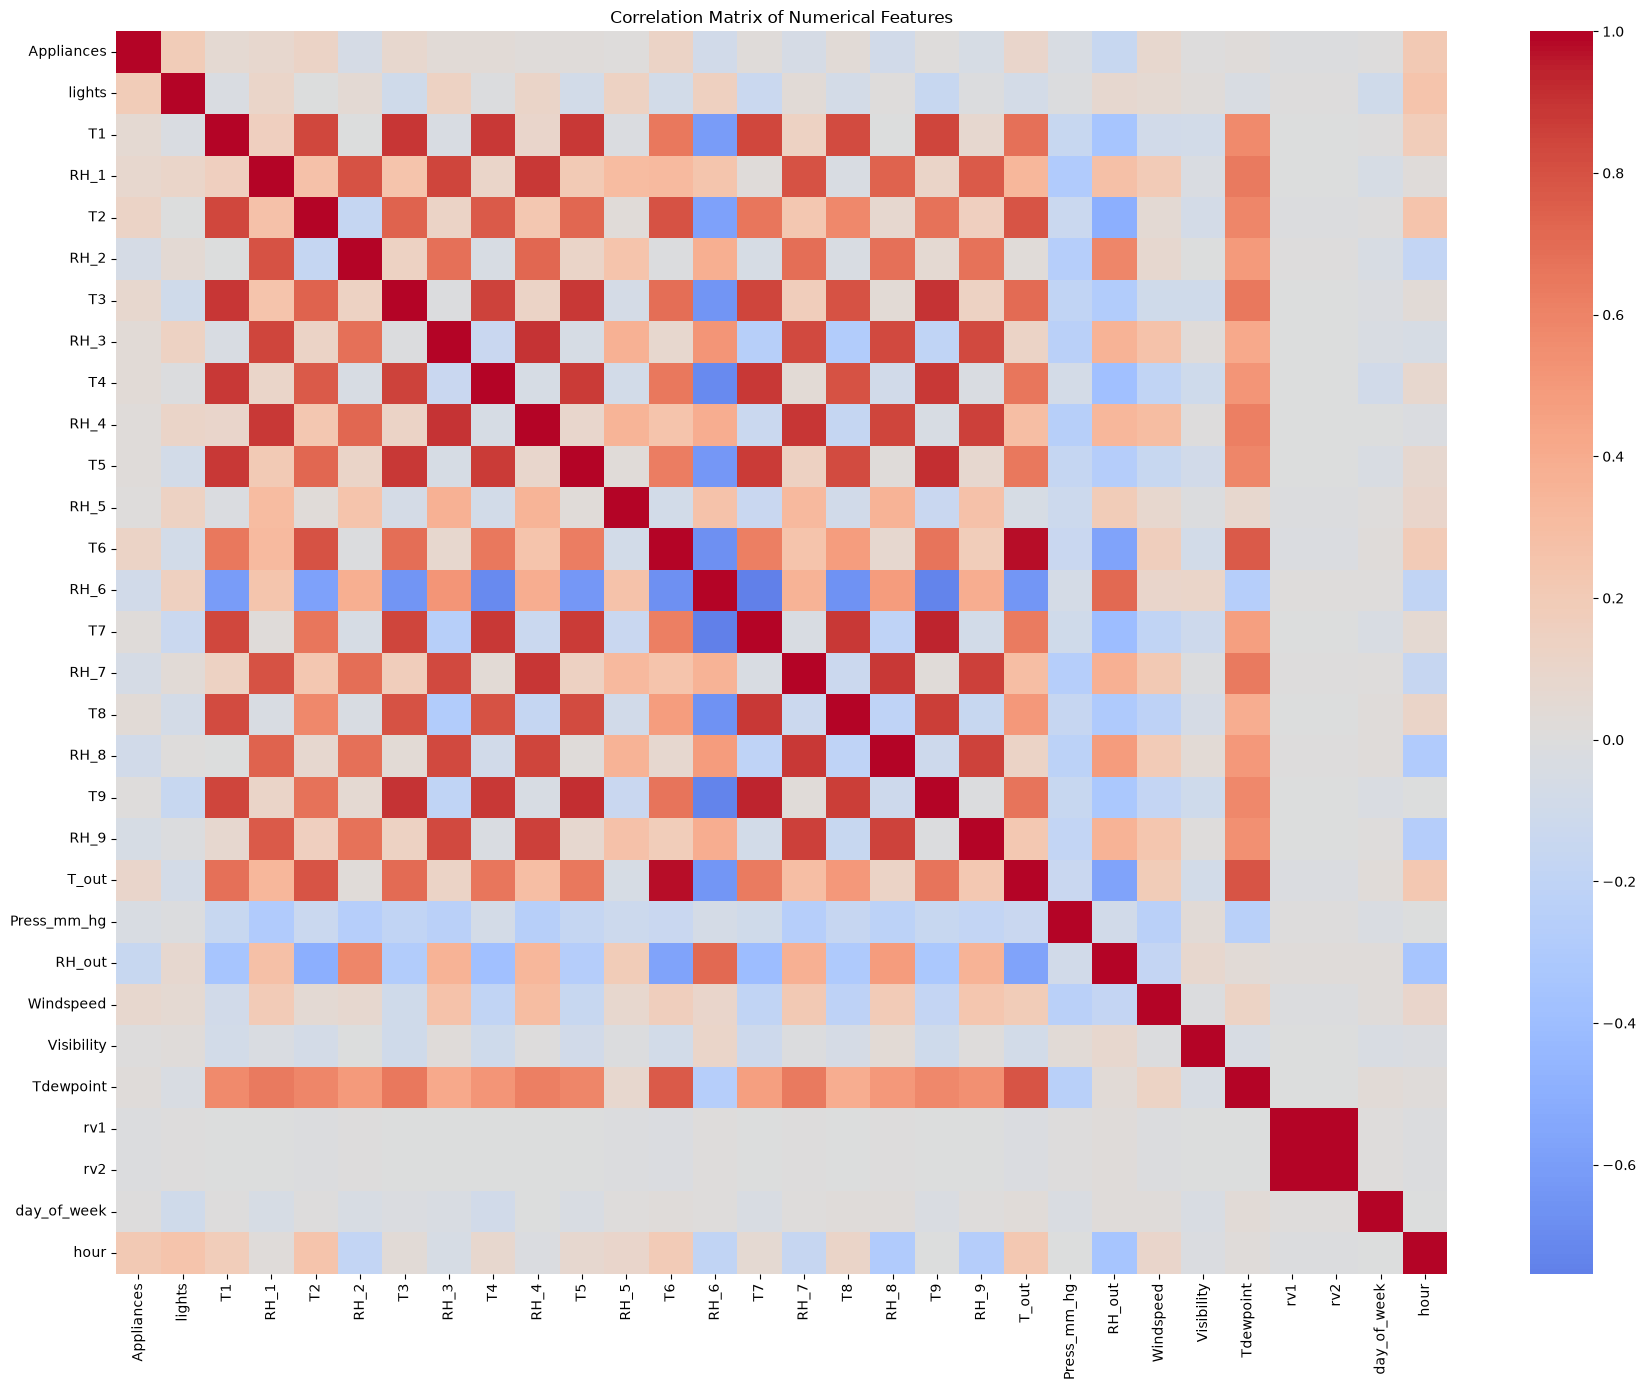

In [31]:
correlation_matrix = df.select_dtypes(include='number').corr()

appliances_correlations = correlation_matrix['Appliances'].sort_values(
    ascending=False
)

#display(appliances_correlations)

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

## 6. EDA Conclusions and Preprocessing Decisions

### 1. Dataset Structure

- <span style="color:#e57373"><strong>Finding:</strong></span> The dataset contains 19,735 observations and 29 columns. Measurements are recorded at 10-minute intervals, and the `date` column is initially stored as text.
- <span style="color:#81c784"><strong>Decision:</strong></span> We will convert `date` to the `datetime` format and use its temporal information to create additional features for modelling.

### 2. Data Quality

- <span style="color:#e57373"><strong>Finding:</strong></span> No missing values or duplicate rows were identified in the original dataset.
- <span style="color:#81c784"><strong>Decision:</strong></span> No imputation method is necessary for the original data.

### 3. Removal of Artificial Attributes

- <span style="color:#e57373"><strong>Finding:</strong></span> The `rv1` and `rv2` variables contain identical values and represent artificial random variables, according to the UCI documentation.
- <span style="color:#81c784"><strong>Decision:</strong></span> Both attributes will be removed from the feature set used for model training.

### 4. Target Variable Distribution (`Appliances`)

- <span style="color:#e57373"><strong>Finding:</strong></span> Energy consumption has a positively skewed distribution, with numerous high values identified as potential outliers.
- <span style="color:#81c784"><strong>Decision:</strong></span> These observations will not be removed automatically, as they may represent genuine consumption events. A logarithmic transformation will remain an optional experiment to evaluate later.

### 5. Temporal Characteristics

- <span style="color:#e57373"><strong>Finding:</strong></span> The temporal analysis reveals variations in consumption depending on the hour and day of the week, as well as strong autocorrelation between observations close in time.
- <span style="color:#81c784"><strong>Decision:</strong></span> We will investigate the use of historical consumption values (lag features) and temporal features to improve forecasting performance.

### 6. Correlation Between Features

- <span style="color:#e57373"><strong>Finding:</strong></span> Most features have relatively weak linear correlations with the target variable. However, some temperature and humidity measurements are strongly correlated with one another.
- <span style="color:#81c784"><strong>Decision:</strong></span> We will initially retain the relevant features and evaluate their contribution during model training and comparison.